# LightGBM

## Clasificador

In [1]:
import pandas as pd

df = pd.read_csv(
    "http://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
    header=None,
    names=['age', 'workclass', 'fnlwgt', 'education', 'education-num',
           'marital-status', 'occupation', 'relationship','race', 'sex',
           'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'],
    na_values=' ?'
    )

df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


Para que funcione el procesamiento nativo de variables categóricas, es necesario convertir estas variables de tipo **object** (o **str**) a tipo **category**:

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X = df.drop('income', axis=1)
y = df['income']

orden = [
    ' Preschool', ' 1st-4th', ' 5th-6th', ' 7th-8th', ' 9th', ' 10th',' 11th', ' 12th',
    ' HS-grad',' Some-college', ' Assoc-acdm', ' Assoc-voc', ' Bachelors', ' Masters',
    ' Prof-school', ' Doctorate'
         ]
X['education'] = pd.Categorical(X['education'], categories=orden, ordered=True)

categorical_features = X.select_dtypes(include='object').columns.to_list()
X[categorical_features] = X[categorical_features].astype('category')

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1,
    stratify=y
    )

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.fit_transform(y_test)

Se va a entrenar un modelo sin sintonizar hiperparámetros:

In [4]:
from lightgbm import LGBMClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

lgb_model = LGBMClassifier(
    objective='binary',
    scale_pos_weight=scale_pos_weight,
    random_state=1,
    verbose=-1,
    n_jobs=-1
)

lgb_model.fit(
    X_train,
    y_train,
    )

print(f'Train score: {lgb_model.score(X_train, y_train):.3f}')
print(f'Test score: {lgb_model.score(X_test, y_test):.3f}')

Train score: 0.856
Test score: 0.836


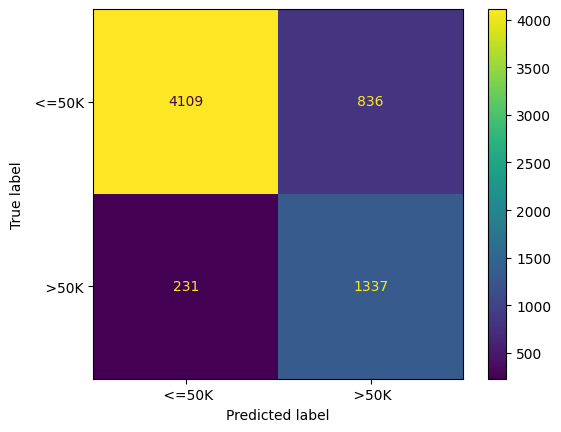

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    lgb_model, 
    X_test, 
    y_test, 
    display_labels=le.classes_
    );

In [6]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test, 
    lgb_model.predict(X_test), 
    target_names=le.classes_
    ))

              precision    recall  f1-score   support

       <=50K       0.95      0.83      0.89      4945
        >50K       0.62      0.85      0.71      1568

    accuracy                           0.84      6513
   macro avg       0.78      0.84      0.80      6513
weighted avg       0.87      0.84      0.84      6513



Ahora se va a sintonizar:

In [7]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

dist_lgb = {
    'n_estimators': randint(50, 400),
    'max_depth': randint(3, 8),
    'num_leaves': randint(20, 100),
    'learning_rate': loguniform(0.01, 0.3),
    'min_child_samples': randint(10, 50),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_alpha': loguniform(1e-3, 10),
    'reg_lambda': loguniform(1e-3, 10)
}

rs_lgb = RandomizedSearchCV(
    estimator=lgb_model,
    param_distributions=dist_lgb,
    n_iter=20,
    scoring='f1_weighted',
    cv=3,
    random_state=1,
    n_jobs=-1
)

rs_lgb.fit(X_train, y_train)

print(f'Mejor F1 ponderado: {rs_lgb.best_score_:.3f}')
print(f'Parámetros óptimos: {rs_lgb.best_params_}')
print(f'Train score: {rs_lgb.score(X_train, y_train):.3f}')
print(f'Test score: {rs_lgb.score(X_test, y_test):.3f}')

Mejor F1 ponderado: 0.848
Parámetros óptimos: {'colsample_bytree': np.float64(0.867898414721392), 'learning_rate': np.float64(0.24093763668497112), 'max_depth': 7, 'min_child_samples': 47, 'n_estimators': 302, 'num_leaves': 48, 'reg_alpha': np.float64(0.0012869165107815027), 'reg_lambda': np.float64(0.4806954824961602), 'subsample': np.float64(0.7669219209468507)}
Train score: 0.935
Test score: 0.852


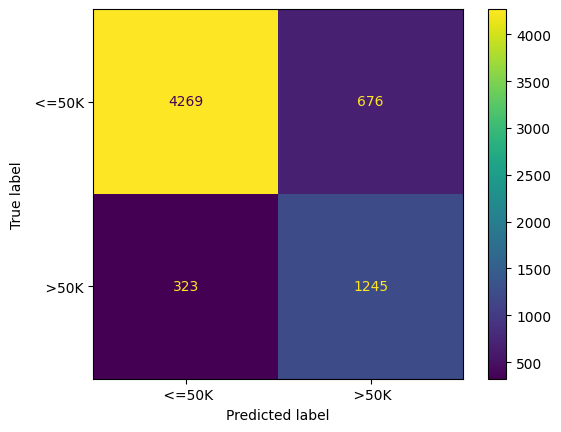

In [8]:
ConfusionMatrixDisplay.from_estimator(
    rs_lgb.best_estimator_,
    X_test,
    y_test,
    display_labels=le.classes_
    );

In [9]:
print(classification_report(
    y_test,
    rs_lgb.best_estimator_.predict(X_test),
    target_names=le.classes_
    ))

              precision    recall  f1-score   support

       <=50K       0.93      0.86      0.90      4945
        >50K       0.65      0.79      0.71      1568

    accuracy                           0.85      6513
   macro avg       0.79      0.83      0.80      6513
weighted avg       0.86      0.85      0.85      6513



Este modelo también da información acerca de la importancia relativa de cada característica:

In [10]:
lgb_features = pd.DataFrame({
    'Feature': rs_lgb.best_estimator_.feature_names_in_,
    'Importance': rs_lgb.best_estimator_.feature_importances_
})

lgb_features.sort_values('Importance', ascending=False)

,Feature,Importance
2,fnlwgt,3306
0,age,2753
12,hours-per-week,1396
3,education,992
6,occupation,767
10,capital-gain,526
11,capital-loss,393
4,education-num,317
1,workclass,288
13,native-country,247


## Regresor

In [11]:
from pathlib import Path

data_dir = Path().resolve().parent / "data" / "raw"
data_name = "home_data.csv"
filepath = data_dir / data_name

df = pd.read_csv(filepath)
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [12]:
from sklearn.model_selection import train_test_split

df = df.drop(columns=['id', 'date'], axis=1)

X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1
    )

print(X_train.shape)
print(X_test.shape)

(17290, 18)
(4323, 18)


In [13]:
from lightgbm import LGBMRegressor
from sklearn.metrics import root_mean_squared_error

lgb_model = LGBMRegressor(
    objective='regression',
    random_state=1,
    verbose=-1,
    n_jobs=-1
)


lgb_model.fit(X_train, y_train)

train_score = root_mean_squared_error(y_train, lgb_model.predict(X_train))
test_score = root_mean_squared_error(y_test, lgb_model.predict(X_test))
print(f'Train score: {train_score:.3f}')
print(f'Test score: {test_score:.3f}')

Train score: 82180.186
Test score: 150712.140


In [14]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

dist_lgb = {
    'n_estimators': randint(50, 400),
    'max_depth': randint(3, 8),
    'num_leaves': randint(20, 100),
    'learning_rate': loguniform(0.01, 0.3),
    'min_child_samples': randint(10, 50),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_alpha': loguniform(1e-3, 10),
    'reg_lambda': loguniform(1e-3, 10)
}

rs_lgb = RandomizedSearchCV(
    estimator=lgb_model,
    param_distributions=dist_lgb,
    n_iter=20,
    scoring='neg_root_mean_squared_error',
    cv=3,
    random_state=1,
    n_jobs=-1
)

rs_lgb.fit(X_train, y_train)

print(f'Mejor RMSE: {-rs_lgb.best_score_:.3f}')
print(f'Parámetros óptimos: {rs_lgb.best_params_}')
print(f'Train RMSE: {-rs_lgb.score(X_train, y_train):.3f}')
print(f'Test RMSE: {-rs_lgb.score(X_test, y_test):.3f}')

Mejor RMSE: 118556.801
Parámetros óptimos: {'colsample_bytree': np.float64(0.8686616389688537), 'learning_rate': np.float64(0.040575196194522524), 'max_depth': 6, 'min_child_samples': 14, 'n_estimators': 330, 'num_leaves': 63, 'reg_alpha': np.float64(0.5571905096939267), 'reg_lambda': np.float64(2.1802318892988546), 'subsample': np.float64(0.6073153109376767)}
Train RMSE: 81267.974
Test RMSE: 148184.427


In [15]:
lgb_features = pd.DataFrame({
    'Feature': rs_lgb.best_estimator_.feature_names_in_,
    'Importance': rs_lgb.best_estimator_.feature_importances_
})

lgb_features.sort_values('Importance', ascending=False)

,Feature,Importance
14,lat,1621
15,long,1427
2,sqft_living,987
11,yr_built,889
3,sqft_lot,832
9,sqft_above,829
16,sqft_living15,760
13,zipcode,681
8,grade,527
17,sqft_lot15,519
